## Multi-Layer Perceptrons (MLPs)

There are three more concepts to cover before we can implement the Transformer architecture:
- multi-layer perceptrons (MLPs)
- layer normalization and,
- residual connections.

In this notebook, we will implement MLPs.

### Normalizing activations with layer normalization
- Layer normalization, also known as LayerNorm (Ba et al. 2016), centers the activations of a neural network layer around a mean of 0 and normalizes their variance to 1
- This stabilizes training and enables faster convergence to effective weights
- Layer normalization is applied both before and after the multi-head attention module within the transformer block, which we will implement later; it's also applied before the final output layer

In [ ]:
import torch
import torch.nn as nn

# Seed so randomly initialized layers / inputs (and their printed outputs)
# are reproducible across runs.
torch.manual_seed(123)

In [32]:
# Let's create 2 training examples with 5 dimensions (features) each
batch_example = torch.randn(2, 5)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
output = layer(batch_example)
print(output)

tensor([[0.0000, 0.2746, 0.7191, 0.0877, 0.1823, 0.5365],
        [0.0000, 0.3683, 0.0000, 0.2865, 0.0000, 0.0000]],
       grad_fn=<ReluBackward0>)


- Let's compute mean and variance for the outputs for each of the two training examples above

In [40]:
mean = output.mean(dim=-1, keepdim=True)
var = output.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.3000],
        [0.1091]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0762],
        [0.0293]], grad_fn=<VarBackward0>)


- The normalization is applied to each of the two inputs (rows) independently; using dim=-1 applies the calculation across the last dimension (in this case, the feature dimension) instead of the row dimension

- **How to apply**:
    - Subtracting the mean and dividing by the square-root of the variance (which is simply standard deviation - the measure of spread) centers the inputs to have a mean of 0 and a variance of 1 across the column (feature) dimension:
    - **Variance** - average of squared differences from the mean
    - **Standard deviation** - square root of variance (better for inutive understanding as it's in same units as the data)

- We use torch.var() instead of torch.std() for efficiency, better control (if we want to add eps to variance before sqrt) and numerical stability.

In [41]:
out_norm = (output - mean) / torch.sqrt(var)
print("Normalized layer outputs:\n", out_norm)

new_mean = out_norm.mean(dim=-1, keepdim=True)
new_var = out_norm.var(dim=-1, keepdim=True)
print("New mean: \n", new_mean)
print("New variance: \n", new_var)

Normalized layer outputs:
 tensor([[-1.0866, -0.0921,  1.5178, -0.7691, -0.4264,  0.8564],
        [-0.6381,  1.5151, -0.6381,  1.0373, -0.6381, -0.6381]],
       grad_fn=<DivBackward0>)
New mean: 
 tensor([[ 4.9671e-08],
        [-1.9868e-08]], grad_fn=<MeanBackward1>)
New variance: 
 tensor([[1.],
        [1.]], grad_fn=<VarBackward0>)


- Each input is centered at 0 and has a unit variance of 1; to improve readability, we can disable PyTorch's scientific notation:

In [42]:
torch.set_printoptions(sci_mode=False)
print("New Mean:\n", new_mean)
print("New Variance:\n", new_var)

New Mean:
 tensor([[     0.0000],
        [    -0.0000]], grad_fn=<MeanBackward1>)
New Variance:
 tensor([[1.],
        [1.]], grad_fn=<VarBackward0>)


- Now, Let's use the same idea so that we can implement a `LayerNorm` class:

In [43]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

**Scale and shift**

- Note that in addition to performing the normalization by subtracting the mean and dividing by the variance, we added two trainable parameters, a `scale` and a `shift` parameter
- The initial `scale` (multiplying by 1) and `shift` (adding 0) values don't have any effect; however, `scale` and `shift` are trainable parameters that the LLM automatically adjusts during training if it is determined that doing so would improve the model's performance on its training task
- This allows the model to learn appropriate scaling and shifting that best suit the data it is processing
- Note that we also add a smaller value (`eps`) before computing the square root of the variance; this is to avoid division-by-zero errors if the variance is 0


**Biased variance**
- In the variance calculation above, setting `unbiased=False` means using the formula $\frac{\sum_i (x_i - \bar{x})^2}{n}$ to compute the variance where n is the sample size (here, the number of features or columns); this formula does not include Bessel's correction (which uses `n-1` in the denominator), thus providing a biased estimate of the variance 
- For LLMs, where the embedding dimension `n` is very large, the difference between using n and `n-1`
 is negligible
- However, GPT-2 was trained with a biased variance in the normalization layers, which is why we also adopted this setting for compatibility reasons with the pretrained weights that we will load in later chapters

- Let's now try out `LayerNorm` in practice:

In [45]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)

In [47]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, keepdim=True)

print("Normalized layer output:\n", out_ln)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer output:
 tensor([[ 0.8960, -0.0366,  1.0097, -1.3979, -0.4713],
        [-1.5307,  0.6293, -0.5116,  0.7243,  0.6888]], grad_fn=<AddBackward0>)
Mean:
 tensor([[    0.0000],
        [    0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


## Implementing a feed forward network with GELU activations

- In this section, we implement a small neural network submodule that is used as part of the transformer block in LLMs
- We start with the activation function
- In deep learning, ReLU (Rectified Linear Unit) activation functions are commonly used due to their simplicity and effectiveness in various neural network architectures
- In LLMs, various other types of activation functions are used beyond the traditional ReLU; two notable examples are GELU (Gaussian Error Linear Unit) and SwiGLU (Swish-Gated Linear Unit)
- GELU and SwiGLU are more complex, smooth activation functions incorporating Gaussian and sigmoid-gated linear units, respectively, offering better performance for deep learning models, unlike the simpler, piecewise linear function of ReLU

- GELU ([Hendrycks and Gimpel 2016](https://arxiv.org/abs/1606.08415)) can be implemented in several ways; the exact version is defined as GELU(x)=x⋅Φ(x), where Φ(x) is the cumulative distribution function of the standard Gaussian distribution.
- In practice, it's common to implement a computationally cheaper approximation: $\text{GELU}(x) \approx 0.5 \cdot x \cdot \left(1 + \tanh\left[\sqrt{\frac{2}{\pi}} \cdot \left(x + 0.044715 \cdot x^3\right)\right]\right)
$ (the original GPT-2 model was also trained with this approximation)

In [60]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        x = 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))
        return x
    
class RELU(nn.Module):
    def __init__(self):
        super().__init__()
    
    def forward(self, x):
        x = torch.clamp(x, min=0)
        return x

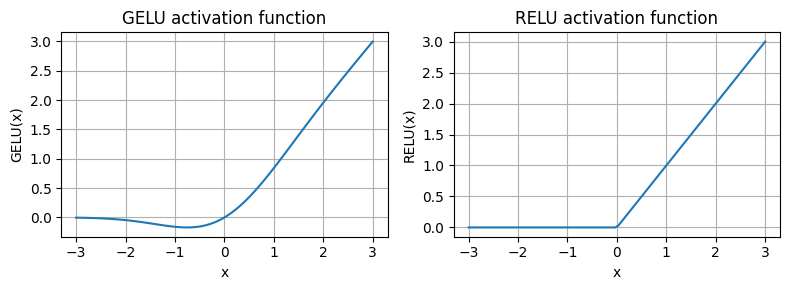

In [64]:
gelu, relu = GELU(), RELU()

import matplotlib.pyplot as plt

# some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "RELU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

- As we can see, ReLU is a piecewise linear function that outputs the input directly if it is positive; otherwise, it outputs zero
- GELU is a smooth, non-linear function that approximates ReLU but with a non-zero gradient for negative values (except at approximately -0.75)

- Next, let's implement the small neural network module, `FeedForward`, that we will be using in the LLM's transformer block later:

In [118]:
class FeedForward(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(emb_dim, 4 * emb_dim),
            GELU(),
            nn.Linear(4 * emb_dim, emb_dim)
        )
    
    def forward(self, x):
        x = self.layers(x)
        return x

In [72]:
ffn = FeedForward(emb_dim=768)

# input shape: [batch_size, num_token, emb_size]
x = torch.rand(2, 3, 768)
out = ffn(x)
print("FFN Output:\n", out)
print("Input:\n", x)


FFN Output:
 tensor([[[ 0.2121, -0.0066, -0.0107,  ...,  0.0744, -0.0069,  0.0797],
         [ 0.2120, -0.0312,  0.0759,  ..., -0.0134, -0.0688,  0.0394],
         [ 0.1985, -0.0399, -0.0195,  ...,  0.0662, -0.1296,  0.1641]],

        [[ 0.1172, -0.0345,  0.0326,  ...,  0.0624, -0.0263,  0.0644],
         [ 0.1551, -0.0661,  0.0934,  ..., -0.0500,  0.0460,  0.0632],
         [ 0.1462,  0.0572,  0.0070,  ...,  0.0278,  0.0235,  0.0500]]],
       grad_fn=<ViewBackward0>)
Input:
 tensor([[[0.8668, 0.3262, 0.5640,  ..., 0.5300, 0.2306, 0.5880],
         [0.8951, 0.7841, 0.7017,  ..., 0.1850, 0.3901, 0.9218],
         [0.6384, 0.4097, 0.3673,  ..., 0.4576, 0.6692, 0.9845]],

        [[0.7127, 0.1634, 0.8677,  ..., 0.5470, 0.9884, 0.0726],
         [0.2353, 0.7401, 0.7881,  ..., 0.8841, 0.0810, 0.0224],
         [0.1441, 0.3265, 0.5605,  ..., 0.4723, 0.6519, 0.2425]]])


## Adding shortcut connections (Residual connections)

- Next, let's talk about the concept behind shortcut connections, also called skip or residual connections
- Originally, shortcut connections were proposed in deep networks for computer vision (residual networks) to mitigate vanishing gradient problems
- A shortcut connection creates an alternative shorter path for the gradient to flow through the network
- This is achieved by adding the output of one layer to the output of a later layer, usually skipping one or more layers in between
- Let's illustrate this idea with a small example network:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/12.webp?123" width="400px">

- In code, it looks like this:

In [82]:
class ExampleDNN(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            l_out = layer(x) # Layer output
            # Checking if shortcut can be applied
            if self.use_shortcut and x.shape == l_out.shape:
                x = x + l_out
            else:
                x = l_out
        return x
    

def print_gradients(model, x):
    # forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # calculate loss
    loss = nn.MSELoss()
    loss = loss(output, target)

    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # print the mean absolute gradients of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")


- Let's print the gradient values first **without** shortcut connections:

In [83]:
layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])

model_without_shortcut = ExampleDNN(layer_sizes, use_shortcut=False)
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 7.174699567258358e-05
layers.1.0.weight has gradient mean of 5.913346103625372e-05
layers.2.0.weight has gradient mean of 0.00013398745795711875
layers.3.0.weight has gradient mean of 0.003962484188377857
layers.4.0.weight has gradient mean of 0.08092202246189117


- Next, let's print the gradient values **with** shortcut connections:

In [84]:
model_with_shortcut = ExampleDNN(layer_sizes, use_shortcut=True)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.4804393947124481
layers.1.0.weight has gradient mean of 0.43162187933921814
layers.2.0.weight has gradient mean of 0.10938365757465363
layers.3.0.weight has gradient mean of 0.32036328315734863
layers.4.0.weight has gradient mean of 2.6919105052948


- As we can see based on the output above, shortcut connections prevent the gradients from vanishing in the early layers (towards `layer.0`)
- We will use this concept of a shortcut connection next when we implement a transformer block

## Connecting attention and linear layers in a transformer block

- In this section, we now combine the previous concepts into a so-called transformer block
- A transformer block combines the causal multi-head attention module from the previous chapter with the linear layers, the feed forward neural network we implemented in an earlier section
- In addition, the transformer block also uses dropout and shortcut connections

In [ ]:
# Ideally import MHA from previous but lets copy paste it from previous nb

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim) 
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2) 
        
        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec) # optional projection

        return context_vec

In [92]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.attn = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg['qkv_bias']
        )
        self.ffn = FeedForward(cfg["emb_dim"])
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
    
    def forward(self, x):
        # shortcut connection for attn block
        shortcut = x
        x = self.norm1(x)
        x = self.attn(x) # shape: [batch, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut # add the original input back - residual

        # shortcut connection for ffn
        shortcut = x
        x = self.norm2(x)
        x = self.ffn(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x


<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/13.webp?1" width="400px">

- Suppose we have 2 input samples with 6 tokens each, where each token is a 768-dimensional embedding vector; then this transformer block applies self-attention, followed by linear layers, to produce an output of similar size
- You can think of the output as an augmented version of the context vectors we discussed earlier

In [93]:
cfg = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [98]:
x = torch.rand(2, 4, 768)  # Shape: [batch_size, num_tokens, emb_dim]
block = TransformerBlock(cfg=cfg)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


In [ ]:
# Lets check the parameters
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

## Coding the GPT model

- We are almost there: now let's plug in the transformer block into the architecture we coded at the very beginning of this chapter so that we obtain a usable GPT architecture
- Note that the transformer block is repeated multiple times; in the case of the smallest 124M GPT-2 model, we repeat it 12 times:


<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/15.webp" width="400px">

- The corresponding code implementation, where `cfg["n_layers"] = 12`:

In [101]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)
    
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        token_emdeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = token_emdeds + pos_embeds # shape: [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


- Using the configuration of the 124M parameter model, we can now instantiate this GPT model with random initial weights as follows:

In [103]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [107]:
model = GPTModel(cfg)
output = model(batch)

print("Input batch:\n", batch)
print("\nOutput shape:", output.shape)
print(output)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.4051,  0.2599,  0.0172,  ...,  0.2054, -0.2494,  0.1713],
         [-0.5104,  0.5222, -0.4367,  ..., -0.0145, -0.1006,  0.2517],
         [-0.3864, -0.1904,  0.4447,  ...,  0.2069, -0.0437,  1.2528],
         [-0.8725,  0.4811, -0.2542,  ...,  0.9392, -0.4969,  0.0719]],

        [[ 0.4660,  0.0119, -0.0150,  ...,  0.5397, -0.5248,  0.3789],
         [-0.1131,  0.0234, -0.1345,  ...,  1.3060,  0.2463,  1.2032],
         [-0.4981,  0.1096, -0.7517,  ...,  0.2643,  0.0569,  0.4370],
         [-0.1931, -0.0537, -0.0895,  ...,  0.6186, -1.5861,  0.3125]]],
       grad_fn=<UnsafeViewBackward0>)


In [108]:
# Parameters check
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


- As we see above, this model has 163M, not 124M parameters; why?
- In the original GPT-2 paper, the researchers applied weight tying, which means that they reused the token embedding layer (`tok_emb`) as the output layer, which means setting `self.out_head.weight = self.tok_emb.weight`
- The token embedding layer projects the 50,257-dimensional one-hot encoded input tokens to a 768-dimensional embedding representation
- The output layer projects 768-dimensional embeddings back into a 50,257-dimensional representation so that we can convert these back into words (more about that in the next section)
- So, the embedding and output layer have the same number of weight parameters, as we can see based on the shape of their weight matrices
- However, a quick note about its size: we previously referred to it as a 124M parameter model; we can double check this number as follows:

In [109]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


- In the original GPT-2 paper, the researchers reused the token embedding matrix as an output matrix
- Correspondingly, if we subtracted the number of parameters of the output layer, we'd get a 124M parameter model:

In [110]:
total_params_gpt2 =  total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

Number of trainable parameters considering weight tying: 124,412,160


- In practice, I found it easier to train the model without weight-tying, which is why we didn't implement it here
- However, we will revisit and apply this weight-tying idea later when we load the pretrained weights in chapter 5
- Lastly, we can compute the memory requirements of the model as follows, which can be a helpful reference point:

In [111]:
# Calculate the total size in bytes (assuming float32, 4 bytes per parameter)
total_size_bytes = total_params * 4

# Convert to megabytes
total_size_mb = total_size_bytes / (1024 * 1024)

print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


- Exercise: you can try the following other configurations, which are referenced in the [GPT-2 paper](https://scholar.google.com/citations?view_op=view_citation&hl=en&user=dOad5HoAAAAJ&citation_for_view=dOad5HoAAAAJ:YsMSGLbcyi4C), as well.

    - **GPT2-small** (the 124M configuration we already implemented):
        - "emb_dim" = 768
        - "n_layers" = 12
        - "n_heads" = 12

    - **GPT2-medium:**
        - "emb_dim" = 1024
        - "n_layers" = 24
        - "n_heads" = 16
    
    - **GPT2-large:**
        - "emb_dim" = 1280
        - "n_layers" = 36
        - "n_heads" = 20
    
    - **GPT2-XL:**
        - "emb_dim" = 1600
        - "n_layers" = 48
        - "n_heads" = 25

## Generating text

- LLMs like the GPT model we implemented above are used to generate one word at a time

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/16.webp" width="400px">

- The following `generate_text_simple` function implements greedy decoding, which is a simple and fast method to generate text
- In greedy decoding, at each step, the model chooses the word (or token) with the highest probability as its next output (the highest logit corresponds to the highest probability, so we technically wouldn't even have to compute the softmax function explicitly)
- In the next nb, we will implement a more advanced `generate_text` function
- The figure below depicts how the GPT model, given an input context, generates the next word token

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/17.webp" width="600px">

In [112]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):
        
        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]
        
        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)
        
        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]  

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx

- The `generate_text_simple` above implements an iterative process, where it creates one token at a time

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch04_compressed/18.webp" width="600px">

- Let's prepare an input example:

In [114]:
start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_text = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_text.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [115]:
model.eval() # disable dropout

out = generate_text_simple(
    model=model,
    idx=encoded_text, 
    max_new_tokens=6, 
    context_size=cfg["context_length"]
)

print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 14071, 20650, 46711, 30848, 30004,  8712]])
Output length: 10


- Remove batch dimension and convert back into text:

In [116]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am deserves Vector babysoche ell replied


- Note that the model is untrained; hence the random output texts above
- We will train the model in the next chapter